将文本向量化之后，下一步就是进行向量的存储。

## 1、向量数据库的理解

假设你是一名摄影师，拍了大量的照片。为了方便管理和查找，你决定将这些 照片存储 到一个数据库中。传统的 关系型数据库 （如 MySQL、PostgreSQL 等）可以帮助你 存储照片的元数据 ，比如拍摄时间、地点、参数信息等。

但是，当你想要根据 照片的内容（如颜色、纹理、物体等） 进行搜索时，传统数据库将无法满足你的需求，因为它们通常以数据表的形式存储数据，并使用查询语句进行精确搜索。那么此时，向量数据库就可以派上用场。

我们可以构建一个多维的空间使得每张照片特征都存在于这个空间内，并用已有的维度进行表示，比如时间、地点、相机型号、颜色....此照片的信息将作为一个点，存储于其中。以此类推，即可在该空间中构建出无数的点，而后我们将这些点与空间坐标轴的原点相连接，就成为了一条条向量，当这些点变为向量之后，即可利用向量的计算进一步获取更多的信息。当要进行照片的检索时，也会变得更容易更快捷。

注意：在向量数据库中进行检索时，检索并 不是唯一的、精确的 ，而是查询和目标向量 最为相似的一些向量 ，具有模糊性。

延伸思考：只要对图片、视频、商品等素材进行向量化，就可以实现以图搜图、视频相关推荐、相似宝贝推荐等功能。

## 2、常用的向量数据库

LangChain提供了众多向量存储的集成，包括开源的本地向量存储与云托管的私有向量存储。并公开了一个标准接口，可以轻松地在向量存储之间进行交换。

常用向量数据库：

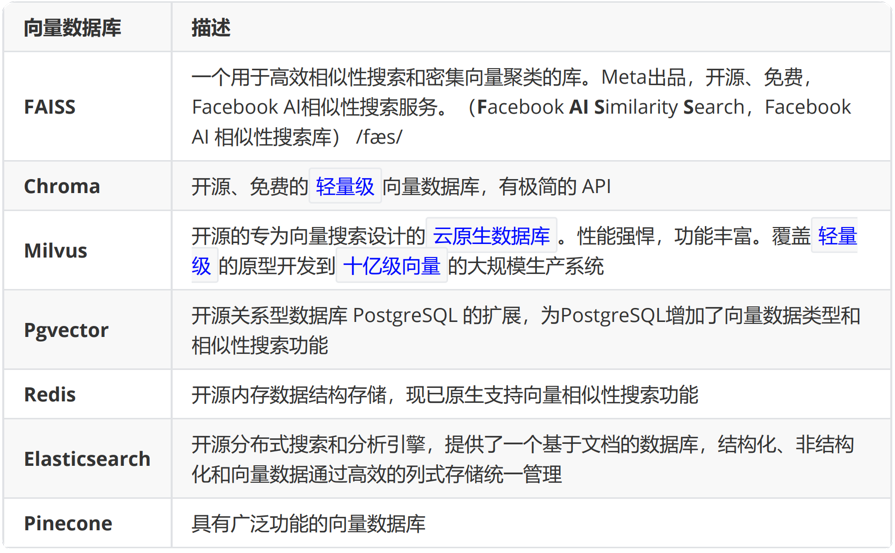

这里我们使用 Milvus 作为向量存储。

## 3、Milvus的使用

### 3.1 Milvus的安装

运行当前目录下的docker-compose文件启动一个单机实例。

### 3.2 安装sdk

```
pip install pymilvus
```
Milvus Lite已包含在Milvus的Python SDK中，此处不用Milvus Lite，直接访问在docker安装的、Standalone模式的Milvus服务。

Milvus Lite 是 Milvus 的轻量本地版，用法类似 SQLite。 在 Python 里给它一个本地路径，例如 MilvusClient("./rag.db")，就能保存向量、按元数据过滤、搜索相似文档，无需启动 Docker。

### 3.3 数据结构

从业务角度，Milvus数据模型层级如下
```
Database -> Collection -> Partition -> Entity
```
- Database：Milvus 的数据库，用来隔离不同业务数据。
- Collection：最核心的逻辑容器，类似于关系型数据库里的 table。
- Partition：分区，是 collection 的子集，不是必须手动创建；一个 collection 至少会有默认partition。
- Entity：可以理解为 collection 中的一条记录。类似于关系型数据库的一行数据。

在传统数据库中，如果你想存储用户信息，你会建一张表叫 user_table ；想存储商品，会建一张表叫product_table 。

在向量数据库中，我们要存储的是成千上万个“特征向量”以及它们对应的文本。为了把不同用途的向量分门别类地存放，我们就要创建不同的 Collection。 比如， COLLECTION_NAME = "docs" 就是给这张“表”取名叫 docs ，专门用来存放你切分好的文档片段向量。

### 3.4 基本用法

#### 3.4.1 DDL操作

In [4]:
from pymilvus import MilvusClient

client = MilvusClient("http://localhost:19530")

# 查看数据库
dbs = client.list_databases()
print("== Databases ==")
for db in dbs:
    print(db)


# 创建数据库
db_name = "rag_tutorial"
if db_name not in dbs:
    client.create_database(db_name)

dbs = client.list_databases()
print("== Databases ==")
for db in dbs:
    print(db)

# 删除数据库
client.drop_database(db_name)

== Databases ==
default
== Databases ==
rag_tutorial
default


如果数据库下有Collection则无法删除，需要先删除它的所有Collection才能删除Database

In [10]:
# 切换数据库
client.use_database(db_name="default")
collections = client.list_collections()
print("== collections ==")
for collection in collections:
    print(collection)

== collections ==


In [7]:
collection_name = "docs"
client.create_collection(
    collection_name=collection_name,
    dimension=1024,
    metric_type="COSINE",
)

dimension ：嵌入向量维度，应和嵌入模型的向量维度保持一致，见下文。

metric_type 表示向量相似度的计算方式， COSINE 表示余弦相似度。
- 当用户提问时，系统会把提问也变成向量，然后去数据库里找“最相似”的本地文本向量。但怎么定义“相似”呢？ 向量数据库需要知道计算规则。 COSINE （余弦相似度）关注的是两个向量在方向上的夹角：
    - 如果两个向量方向完全一致（代表文本意思极度接近），余弦值接近 1 。
    - 如果方向正交（毫无关系），值接近 0 。
    - 结论：在 RAG 检索时，Milvus 会帮你计算用户问题与数据库中所有文本的余弦相似度，并把得分（Score）从大到小排序，把得分最高（最相似）的前 K 个片段还给你。 (注：除了COSINE 之外，常见的还有 L2 欧氏距离、 IP 内积等。)

In [9]:
if client.has_collection(collection_name=collection_name):
    client.drop_collection(collection_name=collection_name)

#### 3.4.2 DML操作

In [11]:
from rich import print as rprint

# 创建collection
collection_name = "docs"
client.create_collection(
    collection_name=collection_name,
    dimension=1024,
    metric_type="COSINE"
)

# 查看 collection 元数据
metadata = client.describe_collection(
    collection_name=collection_name,
)
rprint(metadata)

{
    'collection_name': 'docs',
    'auto_id': False,
    'num_shards': 1,
    'description': '',
    'fields': [
        {
            'field_id': 100,
            'name': 'id',
            'description': '',
            'type': <DataType.INT64: 5>,
            'params': {},
            'is_primary': True
        },
        {
            'field_id': 101,
            'name': 'vector',
            'description': '',
            'type': <DataType.FLOAT_VECTOR: 101>,
            'params': {'dim': 1024}
        }
    ],
    'functions': [],
    'aliases': [],
    'collection_id': 470773398409319902,
    'consistency_level': 2,
    'properties': {'timezone': 'UTC'},
    'num_partitions': 1,
    'enable_dynamic_field': True,
    'enable_namespace': False,
    'created_timestamp': 470773630947557395,
    'update_timestamp': 470773630947557395
}

我们在创建collection时没有指定schema，后者可以理解为表结构，此时Milvus会将collection定义为默认结构。字段信息如下
- id ：数据ID，作为主键唯一标识数据
- vector ：数据的嵌入向量

此外， enable_dynamic_field 为 True ，这表示 collection 支持动态字段。也就是说，除了预定义的id 和 vector 字段之外，在插入数据时还可以携带其他未提前声明的字段，这些字段会被自动写入并 统一存储在动态字段 中。这样做的好处是能够在不修改 schema 的情况下，灵活保存额外的业务属性，例如文本内容、标签、时间戳或来源信息等，适合字段结构不固定的场景。

In [13]:
from langchain.embeddings import init_embeddings
import os
from dotenv import load_dotenv

# 准备测试数据
texts = [
    "LangChain 是一个用于构建 LLM 应用的开发框架。",
    "Milvus 是一个适合 AI 应用的向量数据库。",
    "RAG 的核心是先检索相关知识，再让大模型生成答案。",
    "Docker Desktop 可以方便地在本地运行 Milvus Standalone。"
]

load_dotenv(override=True)

embedding_model = init_embeddings(
    model="qwen3.7-text-embedding-flash",
    provider="openai",
    check_embedding_ctx_length=False,
    api_key=os.getenv("ALIYUN_API_KEY"),
    base_url=os.getenv("ALIYUN_BASE_URL")
)

vectors = embedding_model.embed_documents(texts)

print(len(vectors))
print(len(vectors[0]))
print(vectors[0][:5])

# 封装成可以插入的数据格式,由上可知，collection需要 id字段 作为主键唯一标识数据，需要 vector字段 存储嵌入向量，其余字段可以按需添加。
data = [
    {"id": i, "vector": vectors[i], "text": texts[i], "source": "demo"}
    for i in range(len(texts))
]

# 插入数据
insert_res = client.upsert(
    collection_name=collection_name,
    data=data
)
print("insert result:", insert_res)

# 手动flush，Milvus不会第一时间将数据落盘，要看到写入效果，我们手动flush，将数据刷写到磁盘
client.flush(collection_name=collection_name)

# 查看 collection 统计
stats = client.get_collection_stats(collection_name=collection_name)
print("collection stats:", stats)

4
1024
[-0.005908966064453125, 0.034637451171875, 0.04205322265625, 0.007537841796875, 0.06396484375]
insert result: {'upsert_count': 4, 'ids': [0, 1, 2, 3]}
collection stats: {'row_count': 4}


#### 3.4.3 DQL操作

通过query_iterator 扫描collection下的所有数据

In [ ]:
it = client.query_iterator(
    collection_name=collection_name,
    batch_size=100,
    filter="", # 不加过滤 = 扫全部
    output_fields=["*"] # 你的显式 schema 字段
)

i = 0
while True:
    rows = it.next()
    if not rows:
        break
    for row in rows:
        print("=" * 30, f'-> 第{i + 1}条 <-', "=" * 30)
        print(row)
        print("=" * 30, f'-> 第{i + 1}条 <-', "=" * 30)
        i += 1
it.close()

通过主键查询数据

In [ ]:
res = client.get(
    collection_name=collection_name,
    ids=[0, 1, 2],
)

print(len(res))
for i in range(len(res)):
    print("=" * 30, f'-> 第{i + 1}条 <-', "=" * 30)
    print(res[i])
    print("=" * 30, f'-> 第{i + 1}条 <-', "=" * 30)

相似度检索

In [17]:
# 相似度检索
query = "什么是向量数据库？"
query_vector = embedding_model.embed_query(query)

results = client.search(
    collection_name=collection_name,
    data=[query_vector],
    limit=3,
    output_fields=["text", "source"]
)

print("=== search results ===")
for hit in results[0]:
    print(hit)

=== search results ===
{'id': 1, 'distance': 0.6663029193878174, 'entity': {'text': 'Milvus 是一个适合 AI 应用的向量数据库。', 'source': 'demo'}}
{'id': 3, 'distance': 0.36894041299819946, 'entity': {'text': 'Docker Desktop 可以方便地在本地运行 Milvus Standalone。', 'source': 'demo'}}
{'id': 2, 'distance': 0.3339133858680725, 'entity': {'text': 'RAG 的核心是先检索相关知识，再让大模型生成答案。', 'source': 'demo'}}


limit 表示检索结果最多保留几条数据。

output_fields 表示输出的实体中展示哪些字段。